<!-- d2l:prose id=regularized-md-1 fw=all -->

# KL-Regularized Policy Optimization

Every method of that section and of this chapter so far assumed that someone had written down the reward. For a frozen lake or a cart with a pole that is easy: reach the goal, keep the pole upright. For most tasks people care about it is not. Nobody can write a formula that scores a helpful answer, a safe lane change or a readable proof. People can, however, look at two attempts and say which one they prefer, and a reward can be fitted to such comparisons. This is how the first widely used chat models were taught to be helpful: a reward model was fitted to human comparisons, and a policy was then trained against it [@Christiano.Leike.Brown.ea.2017; @ouyang2022training].

A fitted reward raises a question that a written one never did. The model is accurate only where its comparison data provide information, and it guesses elsewhere, while an optimizer searches everywhere. If the optimizer finds a region that the comparisons never covered and where the fitted reward happens to be high, it goes there, and the true quality falls. The remedy that practice settled on is to charge the policy for moving away from the policy that generated the comparisons, by a penalty on the KL divergence from that reference. The trust region of that section limited how far each update moves from the previous policy. This penalty is part of the objective instead, so it changes the answer and not only the route to it, and the answer has a closed form: the reference distribution reweighted by the exponential of the reward.

We first build a gridworld whose true reward we know, fit a reward from comparisons, and watch an optimizer exploit its gaps. We then solve the penalized problem for one decision, extend the solution to many steps, and trace how the true quality rises and then falls as the policy moves away from its reference.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

<!-- d2l:prose id=regularized-md-2 fw=all -->

## Learning a Reward from Comparisons

To see what goes wrong we need a task whose true reward we know, so that we can hide it from the learner and still grade the result. A small gridworld provides one.

### The Gridworld and Its Reference Policy

The world is a $4 \times 4$ grid with deterministic moves, shown in the figure. An episode starts in the top-left cell and ends when it enters the goal in the bottom-right corner, which pays $+1$. Every other move costs $0.04$, and a move into either of the two hazard cells side by side in the second row, the *hazard lane*, costs $1.5$. The true reward $r^*(s, a)$ is the payment for the cell that action $a$ enters from state $s$. The cells are numbered row by row, so the start is state $0$, the hazards are states $5$ and $6$, and the goal is state $15$. The actions $0$ to $3$ move left, down, right and up, and a move into the wall leaves the agent where it is.

![The gridworld of this section. (a) Episodes start in state 0 (S) and end in the goal, state 15 (G, $+1$); a move into a hazard cell, 5 or 6, costs $1.5$ and every other move $0.04$. Each cell shows in how many of the 1,000 reference trajectories it is visited. (b) The support of every state-action pair: each cell is split into four triangles for the moves left, down, right and up, shaded by the number of trajectories that contain the pair (log scale); a cross marks a pair that never occurs, and the eight moves into the hazard lane are outlined.](../img/mdl-rl-reward-gridworld.svg)

The comparisons will be collected from trajectories of one fixed policy, the *reference policy* $\pi_{\textrm{ref}}$. We make it competent but hesitant: a softmax of the optimal action values at temperature $0.25$, $\pi_{\textrm{ref}}(a \mid s) \propto e^{Q^*(s, a)/0.25}$. At the start, the two moves toward the goal have $Q^* = 0.59$ and the two into the walls $0.52$, so the reference takes each good move with probability $0.28$ and each wasted one with $0.22$. A move into a hazard is worth about $1.5$ less than the alternatives, which the softmax turns into a probability of about $e^{-6}$, so the reference rarely goes there. The cell builds the arrays $P[s, a, s']$ and $r^*[s, a]$ as a `d2l.TabularMDP` (that section), computes $Q^*$ by running `d2l.value_iteration` and applying one more `backup` (that section), and forms the reference:

In [2]:
gamma = 0.95                                   # a 4 x 4 gridworld
P = np.zeros((16, 4, 16))
for s, a in np.ndindex(16, 4):
    x, y = s % 4, s // 4
    dx, dy = [(-1, 0), (0, 1), (1, 0), (0, -1)][a]   # left, down, right, up
    P[s, a, min(3, max(0, y + dy)) * 4 + min(3, max(0, x + dx))] = 1.0
P[15], P[15, :, 15] = 0.0, 1.0                 # the goal absorbs
bonus = np.full(16, -0.04)                     # every step costs a little
bonus[[5, 6]], bonus[15] = -1.5, 1.0           # a hazard lane; the goal pays
r_true = np.einsum('sat,t->sa', P, bonus)      # r*(s, a): the entered bonus
r_true[15] = 0.0
mdp = d2l.TabularMDP(P, r_true, gamma)
Q_true = mdp.backup(d2l.value_iteration(mdp, 200)[-1])
pi_ref = np.exp(Q_true / 0.25)                 # competent but hedging
pi_ref /= pi_ref.sum(1, keepdims=True)

<!-- d2l:prose id=regularized-md-3 fw=all -->

### Preferences and the Bradley-Terry Model

A comparison tells us which of two trajectories a judge preferred, not by how much. The Bradley-Terry model [@Bradley.Terry.1952] turns such answers into a statistical model. It assigns each candidate a scalar score, here the return $r(\tau)$ of a trajectory under the reward $r$, and treats a comparison as a noisy observation of the score difference:

$$P(\tau \succ \tau') = \sigma\big( r(\tau) - r(\tau') \big), \qquad \sigma(u) = \frac{1}{1 + e^{-u}}.$$

Thus two trajectories with equal returns are preferred either way with probability one half, and a difference of one unit of return makes the better one win about three times in four.

In the gridworld the return is linear in the reward. Let $\mathbf{c}(\tau)$ be the discounted visit counts of a trajectory, one entry per state-action pair: entry $(s, a)$ adds $\gamma^t$ for every step $t$ at which the trajectory takes $a$ in $s$. Then $r(\tau) = \mathbf{c}(\tau)^\top r$, with the reward flattened into $64$ entries, and fitting the equation is logistic regression with features $\mathbf{c}(\tau) - \mathbf{c}(\tau')$ and the reward as weights. `sample_traj` returns $\mathbf{c}(\tau)$ for one trajectory of $\pi_{\textrm{ref}}$, which ends at the goal or after $40$ steps, and `X` stacks $1000$ of them. We label $6000$ random pairs by coin flips with the probabilities of the equation under $r^*$ and fit $\hat r$ by gradient ascent on the log-likelihood, with a small weight decay, $0.02$, so that the fit is well defined on pairs with little data. `episodes` counts the episodes in which each pair occurs, `core` marks the pairs that occur in at least $50$, and `into` lists the four moves into the hazard lane from above and from the sides:

In [3]:
rng = np.random.default_rng(0)
sigmoid = lambda u: 1 / (1 + np.exp(-u))

def sample_traj(mdp, pi, rng, T=40):
    """Discounted visit counts c(tau) of one episode from state 0."""
    s, c = 0, np.zeros((16, 4))
    for t in range(T):
        a = rng.choice(4, p=pi[s])
        c[s, a] += mdp.gamma ** t              # the return is c(tau) . r
        s = mdp.P[s, a].argmax()
        if s == 15:
            break
    return c.ravel()

X = np.stack([sample_traj(mdp, pi_ref, rng) for _ in range(1000)])
R = X @ r_true.ravel()                         # true returns; the fit never sees them
i, j = rng.integers(0, 1000, (2, 6000))
y = (rng.random(6000) < sigmoid(R[i] - R[j])).astype(float)
D = X[i] - X[j]
lr, wd, num_steps = 0.5, 0.02, 4000            # ascent step, weight decay
w = np.zeros(64)
for _ in range(num_steps):                     # logistic regression on (D, y)
    w += lr * (D.T @ (y - sigmoid(D @ w)) / len(y) - wd * w)
r_hat = w.reshape(16, 4)
episodes = (X > 0).sum(0).reshape(16, 4)       # episodes containing each pair
core = episodes >= 50
into = ([1, 4, 2, 7], [1, 2, 1, 0])            # into cells 5, 6 from above, sides
print(f'never visited: {(episodes == 0).sum()} pairs; '
      f'in at least 50 episodes: {core.sum()} pairs')
print(f'rms fit error on those {core.sum()}: '
      f'{np.sqrt(((r_hat - r_true)[core] ** 2).mean()):.3f}')
print(f'moves into the hazards: in {episodes[into]} episodes, '
      f'fitted {np.round(r_hat[into], 2)}')

never visited: 9 pairs; in at least 50 episodes: 46 pairs
rms fit error on those 46: 0.193
moves into the hazards: in [3 4 3 2] episodes, fitted [-0.03 -0.05 -0.02 -0.02]


<!-- d2l:prose id=regularized-md-4 fw=all -->

The fit has an rms error of $0.19$ on the forty-six pairs of `core`. Nine pairs never occur: the four actions at the goal, where every episode has already ended, and the five marked with crosses in the figure. Their fitted rewards stay at the initial value of zero. The moves into the hazard lane from above and from the sides occur in two to four of the thousand episodes each, and the two from below never occur. That is too few to move a fitted reward far from zero, where the weights started and where the weight decay pulls them; truly each costs $1.5$. A neural reward model would instead extrapolate according to its inductive bias, for better or worse (exercise 4).

### Invariance to Shaping

An rms error of $0.19$ against step costs of $0.04$ looks large, but most of it is invisible to any comparison. Potential-based shaping, introduced in that section, adds $\gamma \Phi(s') - \Phi(s)$ to the reward of each move from $s$ to $s'$, for a function $\Phi$ on the states with $\Phi = 0$ at the goal, and that section proved that it leaves the optimal policy unchanged. Along a trajectory these terms telescope, so every trajectory from state $0$ that reaches the goal changes its return by the same amount, $-\Phi(0)$. Every comparison involves two trajectories from state $0$, so the shift cancels in $r(\tau) - r(\tau')$, and the equation cannot detect it. (The one trajectory in ten that is cut off after forty steps keeps a final term $\gamma^{40}\Phi(s_{40})$, too small to pin $\Phi$ down.) The comparisons therefore determine the reward only up to shaping, and among the rewards they cannot tell apart, the weight decay prefers the one with the smallest weights.

The cell finds the potential whose shaping term best explains the fit's error on `core`, in the least-squares sense. Row $(s, a)$ of `F` multiplies $\Phi$ to give $\gamma \sum_{s'} P(s' \mid s, a)\, \Phi(s') - \Phi(s)$, and dropping the last column sets $\Phi(15) = 0$:

In [4]:
err = (r_hat - r_true)[core]
F = (gamma * P - np.eye(16)[:, None, :])[core][:, :15]  # shaping per unit of Phi
Phi = np.linalg.lstsq(F, err, rcond=None)[0]
print(f'rms error on core {np.sqrt((err ** 2).mean()):.3f}, after removing '
      f'the best shaping term {np.sqrt(((err - F @ Phi) ** 2).mean()):.3f}')
print(f'Phi(0) = {Phi[0]:.2f}; moves 13 -> 14 -> goal: fitted '
      f'{r_hat[13, 2]:+.2f}, {r_hat[14, 2]:+.2f}, true '
      f'{r_true[13, 2]:+.2f}, {r_true[14, 2]:+.2f}')

rms error on core 0.193, after removing the best shaping term 0.032
Phi(0) = 0.78; moves 13 -> 14 -> goal: fitted -0.08, +0.09, true -0.04, +1.00


<!-- d2l:prose id=regularized-md-5 fw=all -->

Removing the shaping term leaves an rms error of $0.03$: up to shaping, the fit is good where the data are. The potential rises from about $0.8$ at the start to about $0.9$ beside the goal; at the hazard cells, which no pair of `core` touches, it is left undetermined. Such a potential subtracts about $0.9$ from the move into the goal and about $(1 - \gamma) \times 0.8 = 0.04$ from every other move, which is what the printed rewards show: the last move pays $0.09$ instead of $1$, and an ordinary move costs $0.08$ instead of $0.04$. Both rewards order every pair of trajectories from state $0$ alike, and the fitted one has the smaller weights. Under it, the hazard moves, estimated near zero, are cheaper than an ordinary move.

Language models face the same invariance. A comparison there involves two responses $y$ and $y'$ to the same prompt $x$, and a reward $r(x, y) + f(x)$, for any function $f$ of the prompt, predicts every comparison as $r(x, y)$ does, so a learned reward is identified only relative to each prompt (exercise 1). Policy-gradient methods are unaffected: subtracting a function of the prompt from the reward is a baseline, which leaves the expected gradient unchanged (that section). The group mean of GRPO is such a baseline, except that it includes the response's own reward, which scales the expected update by $(K-1)/K$ for groups of $K$ responses, as that section showed.

## Optimizing a Fitted Reward

We now do what an agent would do with the fitted reward: find the policy that maximizes it. With the dynamics known, value iteration finds it. `plan` returns the optimal deterministic policy for a reward as one-hot rows. `ret` returns the exact return of a policy from state $0$ through `policy_value` of that section, which solves the linear Bellman equations $V^\pi = (I - \gamma P_\pi)^{-1} r_\pi$ in one step. We plan once on the true and once on the fitted reward, and grade both plans under both rewards:

In [5]:
def plan(r):
    """Optimal deterministic policy (one-hot rows) for reward r."""
    m = d2l.TabularMDP(P, r, gamma)
    return np.eye(4)[m.backup(d2l.value_iteration(m, 200)[-1]).argmax(1)]

def ret(pi, r):
    """Exact return of policy pi from state 0 under reward r."""
    return d2l.TabularMDP(P, r, gamma).policy_value(pi)[0]

for name, r in (('true reward  ', r_true), ('fitted reward', r_hat)):
    pi = plan(r)
    print(f'plan on {name}: fitted return {ret(pi, r_hat):+.2f}, '
          f'true return {ret(pi, r_true):+.2f}')

plan on true reward  : fitted return -0.24, true return +0.59
plan on fitted reward: fitted return -0.03, true return -2.11


<!-- d2l:prose id=regularized-md-6 fw=all -->

Under the fitted reward the plan on $\hat r$ scores $-0.03$, above the $-0.24$ of the true optimum. The true optimum's fitted score lies $0.83$ below its true score, close to the shaping offset $\Phi(0) = 0.78$, so only differences between fitted scores mean anything. Under the true reward the two plans score $-2.11$ and $+0.59$. The plan on $\hat r$ walks $0 \to 1 \to 5 \to 6 \to 7 \to 11 \to 15$, straight through both hazard cells, a route as short as the safe one along the border and cheaper under $\hat r$. Value iteration optimized the reward it was given; the failure lies in the reward outside the reference's data. Over $24$ preference datasets drawn with different seeds, the plan on $\hat r$ crosses the hazard cells in $19$ and never reaches the goal in $4$ more; one dataset yields the true optimum.

This failure has a name. Goodhart's law states that a measure loses its value once it becomes a target. In reinforcement learning, a policy that scores highly under a specified or fitted reward while defeating the intended objective is said to *hack* the reward, and many cases are catalogued in [@Krakovna.Uesato.Mikulik.ea.2020]. The approach bonus of that section, which made the optimal policy circle forever, was the same mechanism with a hand-written error. Here the error is statistical, and it sits where the data are thin.

## The KL-Regularized Objective

The fitted reward deserves trust only where the reference policy went. A policy that stays close to the reference stays where the data are, so we charge for moving away from it. KL divergence is the natural measure here: it is an expectation under the policy itself, so it can be estimated from the policy's own samples, and it is infinite for a policy that takes an action the reference never takes. For a single decision with reward $r(a)$ over a finite set of actions, a reference $\pi_{\textrm{ref}}$ and a coefficient $\beta > 0$, the *KL-regularized objective* is

$$\max_{\pi}\ \mathbb{E}_{a \sim \pi}\big[ r(a) \big] - \beta\, D_{\textrm{KL}}\big( \pi \Vert \pi_{\textrm{ref}} \big).$$

The first term is the expected reward, and the second subtracts $\beta$ units of reward for every nat of divergence from the reference. The coefficient $\beta$ is the weight of the penalty; the reference stays fixed.

### The Closed-Form Optimum for One Decision

**Proposition.** For $\beta > 0$, the objective the equation is maximized by the unique policy

$$\pi^\star(a) = \frac{1}{Z}\, \pi_{\textrm{ref}}(a)\, e^{r(a)/\beta}, \qquad Z = \sum_{a} \pi_{\textrm{ref}}(a)\, e^{r(a)/\beta},$$

and the maximal value is $\beta \log Z$.

**Proof.** By construction $r(a) = \beta \log\big( \pi^\star(a) Z / \pi_{\textrm{ref}}(a) \big)$. Substituting into the objective, for any policy $\pi$,

$$
\begin{aligned}
\mathbb{E}_\pi[r] - \beta D_{\textrm{KL}}(\pi \Vert \pi_{\textrm{ref}}) &= \sum_a \pi(a)\, \beta \log \frac{\pi^\star(a)\, Z}{\pi(a)} \\
&= \beta \log Z - \beta\, D_{\textrm{KL}}(\pi \Vert \pi^\star).
\end{aligned}
$$

Gibbs' inequality, proved in that section, says the remaining divergence is nonnegative and zero exactly when $\pi = \pi^\star$. $\blacksquare$

Thus the optimum multiplies the reference by an exponential tilt $e^{r/\beta}$ and renormalizes, and the value it achieves is a log-partition function. the figure draws the product for five actions. The reference there is deliberately not monotone in the reward, and its dip at the second action survives a mild tilt: the optimum reweights the reference rather than ranking the actions by reward.

![The optimum of the penalized objective as a product. Each row multiplies the reference $\pi_{\textrm{ref}} = (0.30,\ 0.10,\ 0.25,\ 0.20,\ 0.15)$ by the tilt $e^{r/\beta}$ for the reward $r = (0,\ 0.5,\ 1,\ 2,\ 3)$ and renormalizes, giving $\pi^\star$; the top row uses $\beta = 2$, the bottom $\beta = 0.2$. The reference's dip at $a_2$ survives into $\pi^\star$ in the top row and is overwhelmed in the bottom row. The margins annotate the two limits: $\beta \to \infty$ returns the reference, $\beta \to 0$ a point mass on the best action.](../img/mdl-rl-kl-tilting.svg)

Two boundary cases complete the statement. First, the optimum inherits the reference's support. If $\pi_{\textrm{ref}}(a) = 0$, any policy that puts mass on $a$ has infinite divergence, and the equation gives $a$ probability zero, whatever its reward. Second, as $\beta \to 0$ the optimum concentrates on the best action in the support of $\pi_{\textrm{ref}}$; if several actions tie for best, the limit is the reference renormalized over the tied set.

We check the proposition numerically by solving the equation with an iterative method that knows nothing of the closed form. `solve_kl` runs exponentiated gradient ascent: it multiplies the current policy by the exponential of a step size times the gradient, $r - \beta(\log(\pi/\pi_{\textrm{ref}}) + 1)$, and renormalizes onto the simplex. The $+1$ is the same for every action and cancels in the normalization, so the code drops it:

In [6]:
p_ref = np.array([0.30, 0.10, 0.25, 0.20, 0.15])
r = np.array([0.0, 0.5, 1.0, 2.0, 3.0])

def solve_kl(r, p, beta, steps=3000, eta=0.3):
    pi = np.full_like(p, 1 / len(p))
    for _ in range(steps):                     # exponentiated gradient ascent
        pi = pi * np.exp(eta * (r - beta * np.log(pi / p)))
        pi /= pi.sum()
    return pi

for beta in (5.0, 2.0, 0.5, 0.2):
    pi = solve_kl(r, p_ref, beta)
    print(f'beta = {beta:3}: pi_beta = {np.round(pi, 3)}, '
          f'reward {pi @ r:.2f}, KL {(pi * np.log(pi / p_ref)).sum():.2f}')

beta = 5.0: pi_beta = [0.233 0.086 0.237 0.232 0.212], reward 1.38, KL 0.02
beta = 2.0: pi_beta = [0.146 0.062 0.2   0.264 0.327], reward 1.74, KL 0.15
beta = 0.5: pi_beta = [0.004 0.004 0.025 0.148 0.819], reward 2.78, KL 1.26
beta = 0.2: pi_beta = [0.    0.    0.    0.009 0.991], reward 2.99, KL 1.84


<!-- d2l:prose id=regularized-md-7 fw=all -->

As $\beta$ falls from $5$ to $0.2$ the expected reward rises from $1.38$ to $2.99$ and the divergence from $0.02$ to $1.84$ nats. The two rows of the figure are the optima at $\beta = 2$, with divergence $0.15$ nats, and at $\beta = 0.2$. We now compare each converged iterate with the equation, and the achieved objective with $\beta \log Z$. `pi_star` evaluates the closed form, subtracting the largest reward inside the exponential so that it cannot overflow; the shift cancels in the normalization:

In [7]:
def pi_star(r, p, beta):
    star = p * np.exp((r - r.max()) / beta)    # eq_kl_optimum, stabilized
    return star / star.sum()

gap = max(np.abs(solve_kl(r, p_ref, b) - pi_star(r, p_ref, b)).max()
          for b in (5.0, 2.0, 0.5, 0.2))
pi2 = solve_kl(r, p_ref, 2.0)
print(f'largest gap to the closed form over the ladder: {gap:.1e}')
print(f'objective at beta = 2: numerical '
      f'{pi2 @ r - 2.0 * (pi2 * np.log(pi2 / p_ref)).sum():.6f}, '
      f'beta log Z = {2.0 * np.log(p_ref @ np.exp(r / 2.0)):.6f}')

largest gap to the closed form over the ladder: 1.4e-16
objective at beta = 2: numerical 1.442004, beta log Z = 1.442004


<!-- d2l:prose id=regularized-md-8 fw=all -->

The iterates agree with the closed form to floating-point resolution at every $\beta$, and the objective matches $\beta \log Z$ to six decimal places.

### Four Consequences of the Closed Form

**Without the penalty, the optimum is a point mass.** Letting $\beta \to 0$ in the equation sends all mass to the highest-reward action, or, under ties, to the reference's distribution over the tied set. This is the unregularized problem, whose solution is the argmax. The statement concerns the optimum, not the course of a particular training run. The entropy of the PPO policy in that section fell during training, which is consistent with movement toward the near-deterministic optimum of PPO's lightly entropy-regularized objective. A penalty with a larger weight makes a stochastic policy optimal.

**The coefficient interpolates between the reference and the argmax.** The closed form at a very large and a very small $\beta$:

In [8]:
for beta in (100.0, 0.01):
    print(f'beta = {beta:6}: pi_star = {np.round(pi_star(r, p_ref, beta), 3)}')

beta =  100.0: pi_star = [0.297 0.099 0.25  0.202 0.153]
beta =   0.01: pi_star = [0. 0. 0. 0. 1.]


<!-- d2l:prose id=regularized-md-9 fw=all -->

Large $\beta$ reproduces the reference, small $\beta$ is greedy, and every policy in between is the exact optimum for some value of $\beta$.

**A uniform reference turns the penalty into an entropy bonus.** Against a uniform reference, $D_{\textrm{KL}}(\pi \Vert \textrm{uniform}) = \log |\mathcal{A}| - H(\pi)$, so the penalty is a bonus $\beta H(\pi)$ for entropy plus a constant, and the equation becomes the *maximum-entropy* objective. The closed form specializes to a softmax of the reward:

In [9]:
boltzmann = np.exp(r / 0.5) / np.exp(r / 0.5).sum()
print(np.allclose(pi_star(r, np.full(5, 0.2), 0.5), boltzmann))

True


<!-- d2l:prose id=regularized-md-10 fw=all -->

This is the form of the softmax policies of that section. The Boltzmann exploration rule of that section, with $\beta$ as its temperature, is therefore the exact optimum of a one-step objective with an entropy bonus.

**The optimum is a posterior.** The closed form the equation has the form of Bayes' rule: $\pi_{\textrm{ref}}$ is a prior, $e^{r/\beta}$ an unnormalized likelihood, $\pi^\star$ the posterior and $Z$ the normalizer. Control-as-inference methods build on this identity, reading rewards as log-likelihoods of an event called optimality and regularized policy optimization as variational inference [@Levine.2018; @Korbak.Perez.Buckley.2022].

### The One-Decision Frontier

Each $\beta$ gives one optimum, with an expected reward and a divergence from the reference. Sweeping $\beta$ traces the best reward attainable at each divergence, the *reward-divergence frontier*:

KL 0 pays 1.15; the frontier ends at KL 1.90, reward 3


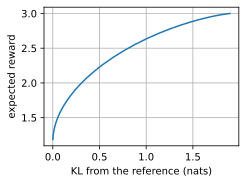

In [10]:
front = np.stack([pi_star(r, p_ref, b) for b in np.logspace(1.5, -1.5, 61)])
kl_f = (front * np.log(front / p_ref)).sum(1)
print(f'KL 0 pays {p_ref @ r:.2f}; the frontier ends at KL '
      f'{np.log(1 / p_ref[r.argmax()]):.2f}, reward {r.max():.0f}')
d2l.plot(kl_f, front @ r, 'KL from the reference (nats)', 'expected reward')

<!-- d2l:prose id=regularized-md-11 fw=all -->

The frontier starts at the reference's average reward, $1.15$, and ends at the point mass on the best action, whose divergence is $\log(1/0.15) = 1.90$ nats. It is increasing and concave, with slope $\beta$ at the optimum for $\beta$ (exercise 5), so each further nat yields less reward. The two rows of the figure are two points on this curve. Best-of-$N$ sampling, which draws $N$ answers from the reference and keeps the one with the highest reward, moves along the same axis without any training: its divergence from the reference is at most $\log N - (N-1)/N$, about $1.8$ nats for $N = 16$ [@Gao.Schulman.Hilton.2023]. On the gridworld we will trace the same kind of curve, but grade it with the true reward instead of the reward being optimized.

### Trust Region versus Penalty

Trust regions and the fixed-reference penalty both use KL divergence, in different roles.

> **Two uses of KL divergence.** A **trust region** (that section) measures divergence from the *previous iterate*. It limits each update and protects a local approximation, and its reference moves after every update. A **fixed-reference penalty** (this section) is part of the objective and moves the optimum to the equation. PPO-style fine-tuning of language models uses both: a clipped surrogate relative to the sampling policy for stable updates, and a reward penalty relative to the frozen initial model to control the final policy [@ouyang2022training].

The closed form shows where a trust region alone leads. Suppose every update solves its trust-region problem exactly, with a weight $\tilde{\beta}$ on the divergence from the previous iterate, $\pi_{k+1} = \operatorname{argmax}_\pi \mathbb{E}_\pi[r] - \tilde{\beta} D_{\textrm{KL}}(\pi \Vert \pi_k)$, starting from $\pi_0 = \pi_{\textrm{ref}}$. By the proposition each step multiplies the policy by $e^{r/\tilde{\beta}}$, so after $k$ steps

$$\pi_k(a) = \frac{\pi_{\textrm{ref}}(a)\, e^{k\, r(a)/\tilde{\beta}}}{\sum_{a'} \pi_{\textrm{ref}}(a')\, e^{k\, r(a')/\tilde{\beta}}},$$

the closed form with coefficient $\tilde{\beta}/k$. As $k$ grows the coefficient goes to zero, and the iterates approach the point mass on the best action. A trust region shapes the path but not the destination; only a fixed reference changes where the iterates converge (exercise 6).

### The Direction of the Divergence

The penalty $D_{\textrm{KL}}(\pi \Vert \pi_{\textrm{ref}})$ is the *reverse* divergence in the taxonomy of that section, an expectation under $\pi$ that can be estimated from the policy's own samples. The closed form shows how it treats an action $a$ whose reward falls short of the best by $\Delta(a) > 0$: relative to the best action, its probability under $\pi^\star$ is its reference probability times $e^{-\Delta(a)/\beta}$. The forward penalty $D_{\textrm{KL}}(\pi_{\textrm{ref}} \Vert \pi)$ is infinite for a policy that drops any action the reference takes, and its optimum keeps every action at a floor of order $\beta / \Delta(a)$ times its reference probability (exercise 7). Both directions keep every action the reference takes at positive probability for every $\beta > 0$. They differ in how fast poor actions fade as $\beta$ shrinks: exponentially in $1/\beta$ under the reverse penalty, only linearly in $\beta$ under the forward one.

## The Soft Backup

The gridworld is not a single decision. In an MDP the penalty is charged at every step, and the objective from state $0$ becomes

$$\mathbb{E}_\pi\Big[\sum_{t \geq 0} \gamma^t \big( r(s_t, a_t) - \beta\, D_{\textrm{KL}}\big( \pi(\cdot \mid s_t) \Vert \pi_{\textrm{ref}}(\cdot \mid s_t) \big) \big)\Big].$$

At each state the policy faces a one-decision problem of the kind just solved. The question is which reward that decision should be tilted by.

### One Step before the End

At the last decision of an episode an action's worth is its reward, and the proposition applies verbatim: the optimum there is the reference tilted by $e^{r/\beta}$, and the state is worth $\beta \log Z$. One step earlier, an action's worth is its reward plus the worth of the state it leads to. That worth is what the optimal policy *there* achieves under the penalty, $\beta \log Z$, which is less than the best reward available there. The optimal policy at the last step takes that best action only with some probability and is charged the penalty as well.

A two-step example makes the difference concrete. Let the five-action decision of the figure with $\beta = 2$ be the last step of an episode; its value is $\beta \log Z = 1.44$, although its best reward is $3$. One step earlier the agent chooses between entering that decision, which pays nothing at once, and stopping with a sure reward of $2$; the reference picks each with probability one half, and there is no discount. The cell tilts the first decision once by the soft value $1.44$ and once by the best reward $3$, and evaluates the penalized objective of both two-step policies:

In [11]:
beta, stop = 2.0, 2.0                          # stopping pays 2 for sure
V_next = beta * np.log(p_ref @ np.exp(r / beta))   # value of the last step
for name, q in (('soft value', V_next), ('best reward', r.max())):
    pi0 = pi_star(np.array([q, stop]), np.array([0.5, 0.5]), beta)
    J = pi0 @ [V_next, stop] - beta * (pi0 * np.log(pi0 / 0.5)).sum()
    print(f'tilt by the {name} {q:.2f}: pi(enter) = {pi0[0]:.2f}, '
          f'objective {J:.3f}')
Z0 = 0.5 * np.exp(V_next / beta) + 0.5 * np.exp(stop / beta)
print(f'beta log Z of the first decision: {beta * np.log(Z0):.3f}')

tilt by the soft value 1.44: pi(enter) = 0.43, objective 1.740
tilt by the best reward 3.00: pi(enter) = 0.62, objective 1.592
beta log Z of the first decision: 1.740


<!-- d2l:prose id=regularized-md-12 fw=all -->

Tilting by the soft value attains the optimum, $\beta \log Z$ of the first decision. Tilting by the best reward values the second decision at $3$, although the penalized policy there earns only $1.44$, so it enters too often and loses about $0.15$. The tilt must use the value that accounts for every later reward *and* every later penalty.

### Soft Value Iteration

Writing this value at every state gives the general form. Let $Q_\beta(s, a)$ be the worth of action $a$ at state $s$ under the penalized objective, and $V_\beta(s)$ the worth of state $s$. Applying the proposition at every state, with $Q_\beta(s, \cdot)$ in the role of the reward,

$$
\begin{aligned}
V_\beta(s) &= \beta \log \sum_a \pi_{\textrm{ref}}(a \mid s)\, e^{Q_\beta(s, a)/\beta}, \\
Q_\beta(s, a) &= r(s, a) + \gamma \sum_{s'} P(s' \mid s, a)\, V_\beta(s'),
\end{aligned}
$$

and the optimal policy is $\pi_\beta(a \mid s) \propto \pi_{\textrm{ref}}(a \mid s)\, e^{Q_\beta(s, a)/\beta}$. These are the Bellman optimality equations of that section with the maximum over actions replaced by a reference-weighted log-sum-exp, a *soft maximum* that tends to the hard maximum over the reference's support as $\beta \to 0$. The hard maximum is biased upward when the action values are noisy estimates, as that section demonstrated; the log-sum-exp, being convex, is biased upward too, only less sharply. With a uniform reference this is the soft value iteration of maximum-entropy reinforcement learning.

Value iteration solved the hard equations by sweeping $V \leftarrow \max_a \textrm{backup}(V)$ from $V = 0$. The same sweep with the soft maximum solves the equation. The proof that the hard sweep contracts (that section) used only two properties of the maximum: it is monotone, and adding a constant to every entry adds that constant to the maximum. The soft maximum has both, so the soft sweep is also a $\gamma$-contraction, for every $\beta > 0$ and every reference (exercise 3). `soft_max` computes the soft maximum of each row of an array of action values, after subtracting the row's maximum for numerical stability, and returns the tilted policy with it. `soft_v` sweeps `backup` followed by `soft_max`:

In [12]:
def soft_max(Q, p, beta):
    """Row-wise beta log sum_a p(a) exp(Q(a) / beta), and the tilted policy."""
    m = Q.max(1, keepdims=True)                # subtracted for stability
    tilt = p * np.exp((Q - m) / beta)
    V = m[:, 0] + beta * np.log(tilt.sum(1))
    return V, tilt / tilt.sum(1, keepdims=True)

def soft_v(mdp, p, beta, num_iters=400):
    """Soft value iteration V <- soft_max(backup(V)); returns V and pi_beta."""
    V = np.zeros(mdp.num_states)
    for _ in range(num_iters):
        V, pi = soft_max(mdp.backup(V), p, beta)
    return V, pi

<!-- d2l:prose id=regularized-md-13 fw=all -->

### True Return against the KL Budget

We now trace the frontier on the gridworld, with one change: the optimizer sees the fitted reward $\hat r$, and we grade with the true one. For each of $36$ values of $\beta$ from $10$ down to $10^{-2.5}$, `soft_v` computes the exact penalized optimum $\pi_\beta$ for $\hat r$, and we record its true return, its fitted return and its divergence from the reference. For the divergence we use the penalty of the MDP objective, $\mathbb{E}_{\pi_\beta}\big[\sum_t \gamma^t D_{\textrm{KL}}\big(\pi_\beta(\cdot \mid s_t) \Vert \pi_{\textrm{ref}}(\cdot \mid s_t)\big)\big]$ from state $0$. It is the KL divergence between the distributions of trajectories that $\pi_\beta$ and $\pi_{\textrm{ref}}$ generate when every episode also ends with probability $1 - \gamma$ after each step (exercise 2). The code weights the per-state divergences `kl` by `visits`, the expected discounted number of visits to each state from state $0$, which one linear solve with the transition matrix of $\pi_\beta$ provides. It also records the largest residual of the equation over the sweep:

largest soft Bellman residual: 0e+00
reference: true return -0.12; beta = 10: KL 0.001, true return -0.10
peak: true return +0.53 at KL 3.7; smallest beta: -1.83 at KL 14.2


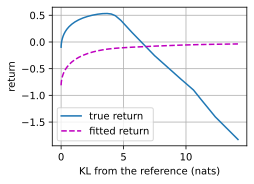

In [13]:
m_hat = d2l.TabularMDP(P, r_hat, gamma)
kls, true_ret, fit_ret, resid = [], [], [], 0.0
for beta in np.logspace(1, -2.5, 36):
    V, pi = soft_v(m_hat, pi_ref, beta)
    V_new, _ = soft_max(m_hat.backup(V), pi_ref, beta)
    resid = max(resid, np.abs(V_new - V).max())
    kl = (pi * np.log(np.where(pi > 0, pi / pi_ref, 1.0))).sum(1)
    P_pi = np.einsum('sa,sat->st', pi, P)
    visits = np.linalg.solve(np.eye(16) - gamma * P_pi.T, np.eye(16)[0])
    kls.append(visits @ kl)                    # discounted KL from state 0
    true_ret.append(ret(pi, r_true))
    fit_ret.append(ret(pi, r_hat))
k = int(np.argmax(true_ret))
print(f'largest soft Bellman residual: {resid:.0e}')
print(f'reference: true return {ret(pi_ref, r_true):+.2f}; beta = 10: '
      f'KL {kls[0]:.3f}, true return {true_ret[0]:+.2f}')
print(f'peak: true return {true_ret[k]:+.2f} at KL {kls[k]:.1f}; '
      f'smallest beta: {true_ret[-1]:+.2f} at KL {kls[-1]:.1f}')
d2l.plot(kls, [true_ret, fit_ret], 'KL from the reference (nats)', 'return',
         legend=['true return', 'fitted return'])

<!-- d2l:prose id=regularized-md-14 fw=all -->

Every point in the plot is an exact optimum of the penalized objective; the largest Bellman residual is below $10^{-10}$. The fitted return rises throughout, and for exact optima it must. If $\beta_1 < \beta_2$ and the optima have fitted returns $J_1, J_2$ and divergences $D_1, D_2$, optimality gives $J_1 - \beta_1 D_1 \geq J_2 - \beta_1 D_2$ and $J_2 - \beta_2 D_2 \geq J_1 - \beta_2 D_1$. Adding the two gives $(\beta_2 - \beta_1)(D_1 - D_2) \geq 0$, so $D_1 \geq D_2$, and the first inequality then gives $J_1 \geq J_2$.

The true return behaves differently. It rises from the reference's $-0.12$ to $+0.53$ at $3.7$ nats, close to the true optimum of $+0.59$, and then falls to $-1.83$ as the policy concentrates on the hazard lane. A moderate push on the fitted reward improves the true return, and a stronger one exploits the moves the data never measured. Over $24$ preference datasets the peak lies between about $+0.5$ and the optimum $+0.59$ at a few nats, and the true return falls after it in $21$. In the other three it does not fall within the swept range: in one the fitted optimum is the true one, and in two the fitted values of the safe and hazard routes nearly tie, so the penalized optimum keeps the safe route down to $\beta = 10^{-2.5}$. How far from the reference the peak sits and how deep the fall goes depend on how well the comparisons cover the hazard and on what it costs. @Gao.Schulman.Hilton.2023 measured the same rise and fall for language models optimized against a learned reward model and graded by a held-out one.

The peak of the true return is invisible to the optimizer, which sees only the fitted curve, and that curve rises monotonically. In practice $\beta$ is therefore chosen by evaluating the policy against something other than the reward model it was trained on: held-out comparisons, human judgments, or a checker. With a uniform reference the same penalty is an entropy bonus, and that section builds an off-policy actor-critic for continuous actions that maximizes it. Its critic evaluates its own policy under the reward with the entropy bonus rather than iterating the log-sum-exp backup; by the identity in the proof of the proposition, the two agree when the policy is the tilted one. that section applies the closed form the equation to the verifier task of that section, where it predicts the $\beta$ at which a hedged answer stops paying. Every method so far has learned from fresh samples of the current policy or from a known model; that section asks whether a network can learn action values from stored transitions of any policy, as the Q-table of that section did.

## Summary

A reward fitted to comparisons is accurate only where the comparisons are. Comparisons between trajectories from a common start cannot see a potential shaping of the reward, and pairs the data never cover keep whatever value the fit started with. An optimizer exploits those gaps: in the gridworld, the plan on the fitted reward walks through hazard cells that the reference rarely entered. Penalizing the KL divergence from the reference changes the objective, and its exact optimum is the reference tilted by $e^{r/\beta}$, with value $\beta \log Z$; a uniform reference turns the penalty into an entropy bonus. In an MDP the tilt uses the soft action value, which satisfies a Bellman equation with a log-sum-exp in place of the maximum. Sweeping the penalty's weight, the fitted return rises monotonically while the true return peaks at a moderate divergence and then falls, so the weight must be chosen by an evaluation the optimizer does not see.

## Exercises

1. **Identifiability and scale.** The Bradley-Terry model
   the equation is fitted to comparisons of two responses $y$ and
   $y'$ to the same prompt $x$.
    1. Show that replacing $r(x, y)$ by $r(x, y) + f(x)$, for any function $f$
       of the prompt, leaves the likelihood of every such dataset unchanged.
       Conversely, join two responses to $x$ by an edge whenever the dataset
       compares them. Show that two rewards that assign the same preference
       probability to every compared pair differ by a constant on each
       connected component of this graph. What is identified when the graph
       of one prompt has several components?
    1. Suppose that the annotators label according to
       $P(y \succ y') = \sigma\big(\omega\, (r^*(x, y) - r^*(x, y'))\big)$ for
       some consistency $\omega > 0$, and that the equation is
       fitted by maximum likelihood on unlimited data. Which reward does the
       fit recover?
    1. Show that the optimum the equation for the fitted reward at
       coefficient $\beta$ is the optimum for $r^*$ at coefficient
       $\beta / \omega$. Suppose that $\beta$ was tuned against a reward
       model fitted to the labels of one pool of annotators. How strong a
       penalty is the same $\beta$ for a reward model fitted to the labels of
       a less consistent pool, that is, one with a smaller $\omega$?
1. [code] **Trajectory divergence.** Let $p_\pi(\tau)$ denote the probability
   that a policy $\pi$, started at state $0$, produces the trajectory
   $\tau = (s_0, a_0, s_1, a_1, \ldots, s_T)$ of a fixed horizon $T$.
    1. Show that
       $$D_{\textrm{KL}}\big(p_\pi \Vert p_{\pi_{\textrm{ref}}}\big) = \mathbb{E}_\pi\Big[\sum_{t=0}^{T-1} D_{\textrm{KL}}\big(\pi(\cdot \mid s_t) \Vert \pi_{\textrm{ref}}(\cdot \mid s_t)\big)\Big].$$
       Which factors of $p_\pi(\tau)$ cancel, and why can the divergence
       therefore be estimated from trajectories of $\pi$ without a model of
       the transitions?
    1. Let the trajectory instead end after each step with probability
       $1 - \gamma$, independently of the actions. Show that the divergence
       between the two trajectory distributions becomes the discounted sum
       of per-state divergences that the sweep of that section
       appends to `kls` as `visits @ kl`.
    1. Take the policy $\pi_\beta$ at the peak of the true return in that
       sweep. Average $\mathbf{c}(\tau)^\top \log(\pi_\beta / \pi_{\textrm{ref}})$,
       with the logarithm taken entrywise and flattened like
       $\mathbf{c}(\tau)$, over 2000 trajectories from
       `sample_traj(mdp, pi, rng, T=400)`, and compare the average with the
       divergence of $3.7$ nats printed at the peak. Some of the
       per-trajectory values are negative. Why does this not contradict
       Gibbs' inequality?
1. [code] **Soft backup on the lake.** The proof in
   that section used one property of the maximum,
   $|\max_a f(a) - \max_a g(a)| \leq \max_a |f(a) - g(a)|$.
    1. Let
       $m_\beta(f) = \beta \log \sum_a \pi_{\textrm{ref}}(a)\, e^{f(a) / \beta}$.
       Show that $m_\beta$ is monotone and that
       $m_\beta(f + c) = m_\beta(f) + c$ for every constant $c$, and deduce
       that $m_\beta$ has the same property as the maximum. Conclude that the
       backup the equation is a $\gamma$-contraction for every
       $\beta > 0$ and every reference.
    1. Apply `soft_v` to the slippery lake of that section, built
       as a `d2l.TabularMDP`, with a uniform reference. Plot
       $V_\beta(s_0)$ against $\beta$ on a logarithmic grid from $10^{-4}$ to
       $10^2$. Which two values computed in that section does the
       curve approach at its two ends? Explain with the regularized objective
       why the curve is monotone.
    1. At about which $\beta$ does $V_\beta(s_0)$ lie halfway between the two
       limits? Compare this coefficient with the differences between the
       optimal action values $Q^*(s_0, a)$ of the lake.
1. [extended] **Neural reward models.** ● The linear fit of `r_hat` leaves
   the pairs without data near zero, whereas a neural reward model
   extrapolates according to its inductive bias. Replace the 64 weights `w`
   by the outputs of a multilayer perceptron with two hidden layers of 64
   ReLU units, one output per state-action pair, and set the row of the goal
   to zero. Train it on the same `D` and `y` with the Bradley-Terry negative
   log-likelihood, Adam at learning rate $0.01$, for 2000 full-batch steps.
    1. Train one model whose input is a one-hot code of the state and the
       action, and one whose input is the two grid coordinates of the state,
       scaled to $[0, 1]$, together with a one-hot code of the action, with
       four seeds each. For every model, report the rms error on `core`, the
       fitted rewards of the moves `into` the hazard cells, and the true
       return of `plan`.
    1. Repeat the sweep of that section on each fitted reward.
       Which representation needs the penalty? Which property of its input
       explains the difference?
1. **Slope of the frontier.** ● Write $u = 1 / \beta$, and let
   $R(u)$ and $D(u)$ denote the expected reward and the
   divergence $D_{\textrm{KL}}(\pi^\star \Vert \pi_{\textrm{ref}})$ of the
   optimum the equation.
    1. Show that $R(u) = \frac{d}{du} \log Z$ and that
       $R'(u) = \textrm{Var}_{\pi^\star}(r)$. Then use the value
       $\beta \log Z$ of the proposition to show that
       $D'(u) = u\, \textrm{Var}_{\pi^\star}(r)$.
    1. Conclude that the frontier traced by `front` and `kl_f` has slope
       $\beta$ at the point $\pi^\star$, and that it is increasing and concave
       whenever $r$ is not constant on the support of $\pi_{\textrm{ref}}$.
    1. Show that $\pi^\star$ also solves the constrained problem
       $\max_\pi \mathbb{E}_\pi[r]$ subject to
       $D_{\textrm{KL}}(\pi \Vert \pi_{\textrm{ref}}) \leq D(u)$. Which
       quantity of the constrained problem does $\beta$ become?
    1. Best-of-$N$ sampling draws $N$ independent samples from
       $\pi_{\textrm{ref}}$ and keeps the one with the highest reward. When
       the reward has a continuous distribution under the reference, show
       that the divergence of the best-of-$N$ distribution from the reference
       is $\log N - (N-1)/N$. For the five-action bandit `p_ref`, `r`, whose
       rewards are distinct and increasing, best-of-$N$ picks action $a$ with
       probability $F(a)^N - F(a-1)^N$, where $F(a)$ is the reference
       probability of the actions up to $a$. Plot its expected reward against
       its divergence for $N = 1, \ldots, 16$, together with `front` and
       `kl_f`. How close does it come to the frontier, and does its
       divergence stay below $\log N - (N-1)/N$?
1. **A moving reference.** ● The trust region of that section measures
   divergence from the previous iterate. This section showed that the
   idealized update
   $\pi_{k+1} = \operatorname{argmax}_\pi\ \mathbb{E}_\pi[r] - \tilde{\beta}\, D_{\textrm{KL}}(\pi \Vert \pi_k)$,
   started at $\pi_0 = \pi_{\textrm{ref}}$, converges to the argmax.
    1. Now add the fixed-reference penalty of the equation, as
       PPO-style fine-tuning does, so that $\pi_{k+1}$ maximizes
       $$\mathbb{E}_\pi[r] - \beta\, D_{\textrm{KL}}(\pi \Vert \pi_{\textrm{ref}}) - \tilde{\beta}\, D_{\textrm{KL}}(\pi \Vert \pi_k).$$
       Show that, up to a constant,
       $$\log \pi_{k+1} = \frac{\beta \log \pi_{\textrm{ref}} + \tilde{\beta} \log \pi_k + r}{\beta + \tilde{\beta}},$$
       and find the limit of $\pi_k$. Which coefficient determines the limit?
       How fast is the limit approached?
    1. Show that the recursion of part a is the update of `solve_kl` with a
       suitable step size, and express that step size through $\beta$ and
       $\tilde{\beta}$. Which of the convergent step sizes of
       `solve_kl` have no interpretation as a trust region?
1. [code] **Forward-KL penalty.** ● that section contrasts
   the reverse divergence of the equation with the forward one.
   Replace the penalty by the forward divergence,
   $$\max_\pi\ \mathbb{E}_{a \sim \pi}\big[r(a)\big] - \beta\, D_{\textrm{KL}}\big(\pi_{\textrm{ref}} \Vert \pi\big).$$
    1. Introduce a multiplier $m$ for the constraint
       $\sum_a \pi(a) = 1$, and show that the optimum is
       $\pi(a) = \beta\, \pi_{\textrm{ref}}(a) / (m - r(a))$, where
       $m > \max_a r(a)$ is the unique value for which these
       probabilities sum to one.
    1. Let $\Delta(a) = \max_{a'} r(a') - r(a) > 0$ be the reward gap of a
       suboptimal action $a$. As $\beta \to 0$, how fast does
       $\pi(a) / \pi_{\textrm{ref}}(a)$ vanish under the forward penalty, and
       how fast under the reverse penalty?
    1. For the five-action bandit `p_ref`, `r`, compute the forward optimum
       by bisection on $m$. For each penalty, find the $\beta$ at which
       the optimum's expected reward is $2.9$, and compare the two optima
       action by action. Which actions receive more probability under the
       forward penalty, and how does this match
       that section?

[Discussions](https://d2l.discourse.group/t/36803)